# Tổng quan về dataset

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from datetime import datetime
import warnings
import os

In [2]:
file_path = '/kaggle/input/datasets/huyenah/calls-for-medical-service-from-2019-to-2026/Fire_Department_Calls_for_Medical_Service_2019_2026.csv'
df = pd.read_csv(file_path, low_memory=False)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 776598 entries, 0 to 776597
Data columns (total 25 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   call_number                     776598 non-null  int64  
 1   incident_number                 776598 non-null  int64  
 2   unit_id                         776598 non-null  object 
 3   unit_type                       776598 non-null  object 
 4   call_type                       776598 non-null  object 
 5   call_type_group                 772473 non-null  object 
 6   call_final_disposition          776598 non-null  object 
 7   original_priority               774141 non-null  object 
 8   priority                        776598 non-null  object 
 9   final_priority                  776598 non-null  int64  
 10  als_unit                        776598 non-null  bool   
 11  number_of_alarms                776598 non-null  int64  
 12  unit_sequence_in

In [3]:
df.head()

,call_number,incident_number,unit_id,unit_type,call_type,call_type_group,call_final_disposition,original_priority,priority,final_priority,...,dispatch_dttm,response_dttm,on_scene_dttm,transport_dttm,hospital_dttm,available_dttm,battalion,station_area,zipcode_of_incident,data_as_of
0,190010008,19000001,89,MEDIC,Medical Incident,Non Life-threatening,Patient Declined Transport,A,2,2,...,2019-01-01T00:01:16.000,2019-01-01T00:01:29.000,2019-01-01T00:02:24.000,NaN,NaN,2019-01-01T00:40:01.000,B05,6.0,94114.0,2024-02-05T03:27:52.000
1,190010044,19000004,66,MEDIC,Medical Incident,Potentially Life-Threatening,Code 2 Transport,3,3,3,...,2019-01-01T00:07:30.000,2019-01-01T00:07:57.000,2019-01-01T00:12:59.000,2019-01-01T00:37:33.000,2019-01-01T00:45:30.000,2019-01-01T01:15:08.000,B05,6.0,94114.0,2024-02-05T03:27:52.000
2,190010051,19000006,81,MEDIC,Medical Incident,Potentially Life-Threatening,Code 2 Transport,3,3,3,...,2019-01-01T00:09:39.000,2019-01-01T00:09:43.000,2019-01-01T00:19:37.000,2019-01-01T00:43:41.000,2019-01-01T00:53:10.000,2019-01-01T01:23:46.000,B09,33.0,94112.0,2024-02-05T03:27:52.000
3,190010050,19000005,99,MEDIC,Outside Fire,Fire,Fire,3,3,3,...,2019-01-01T00:08:34.000,2019-01-01T00:08:43.000,2019-01-01T00:17:10.000,NaN,NaN,2019-01-01T00:41:14.000,B09,39.0,94127.0,2024-02-05T03:27:52.000
4,190010056,19000007,76,MEDIC,Medical Incident,Potentially Life-Threatening,Code 2 Transport,3,3,3,...,2019-01-01T00:10:19.000,2019-01-01T00:10:26.000,2019-01-01T00:11:45.000,2019-01-01T00:32:14.000,2019-01-01T00:38:17.000,2019-01-01T01:14:01.000,B04,41.0,94109.0,2024-02-05T03:27:52.000


In [4]:
df["received_dttm"] = pd.to_datetime(df["received_dttm"])

yearly_range = (
    df.groupby(df["received_dttm"].dt.year)
    .agg(
        count=("call_number", "size"),
        first_call=("received_dttm", "min"),
        last_call=("received_dttm", "max"),
    )
    .assign(
        days=lambda x: (x["last_call"] - x["first_call"]).dt.days + 1,
        avg_calls_per_day=lambda x: (x["count"] / x["days"]).round(1),
    )
)
yearly_range.index.name = "year"

print(yearly_range.to_string())

       count          first_call           last_call  days  avg_calls_per_day
year                                                                         
2019   99122 2019-01-01 00:01:02 2019-12-31 23:54:10   365              271.6
2020   87219 2020-01-01 00:00:18 2020-12-31 23:50:46   366              238.3
2021   88831 2021-01-01 00:04:02 2021-12-31 23:53:12   365              243.4
2022  107837 2022-01-01 00:00:18 2022-12-31 23:58:47   365              295.4
2023  109544 2023-01-01 00:00:28 2023-12-31 23:58:24   365              300.1
2024  104377 2024-01-01 00:02:02 2024-12-31 23:56:18   366              285.2
2025  100320 2025-01-01 00:07:27 2025-12-31 23:56:52   365              274.8
2026   79348 2026-01-01 00:10:20 2026-10-11 03:22:41   284              279.4


Thống kê về thời gian theo từng năm

In [5]:
df["dispatch_dttm"] = pd.to_datetime(df["dispatch_dttm"], errors='coerce')
df["year"] = df["dispatch_dttm"].dt.year

summary = df.groupby("year").agg(
    samples=("call_number", "size"),          
    calls=("call_number", "nunique"), 
    first_recorded_date=("dispatch_dttm", "min"),
    last_recorded_date=("dispatch_dttm", "max"),
)
summary["percentage"] = (summary["samples"] / summary["samples"].sum() * 100).round(2)

print(summary)
print("Tổng:", len(df))

      samples   calls first_recorded_date  last_recorded_date  percentage
year                                                                     
2019    99121   93662 2019-01-01 00:01:16 2019-12-31 23:58:50       12.76
2020    87220   82655 2020-01-01 00:01:19 2020-12-31 23:54:29       11.23
2021    88831   83755 2021-01-01 00:05:03 2021-12-31 23:54:45       11.44
2022   107837  100883 2022-01-01 00:00:53 2022-12-31 23:59:12       13.89
2023   109543  103041 2023-01-01 00:04:12 2023-12-31 23:54:01       14.11
2024   104378   98349 2024-01-01 00:01:08 2024-12-31 23:59:28       13.44
2025   100320   94420 2025-01-01 00:12:01 2025-12-31 23:58:11       12.92
2026    79348   74881 2026-01-01 00:10:34 2026-10-11 03:25:36       10.22
Tổng: 776598


Các cột có missing values:
                     Missing Count  Missing %
hospital_dttm               307036      39.54
transport_dttm              304991      39.27
on_scene_dttm               117316      15.11
response_dttm                11413       1.47
call_type_group               4125       0.53
original_priority             2457       0.32
zipcode_of_incident            475       0.06
available_dttm                 146       0.02
station_area                    31       0.00


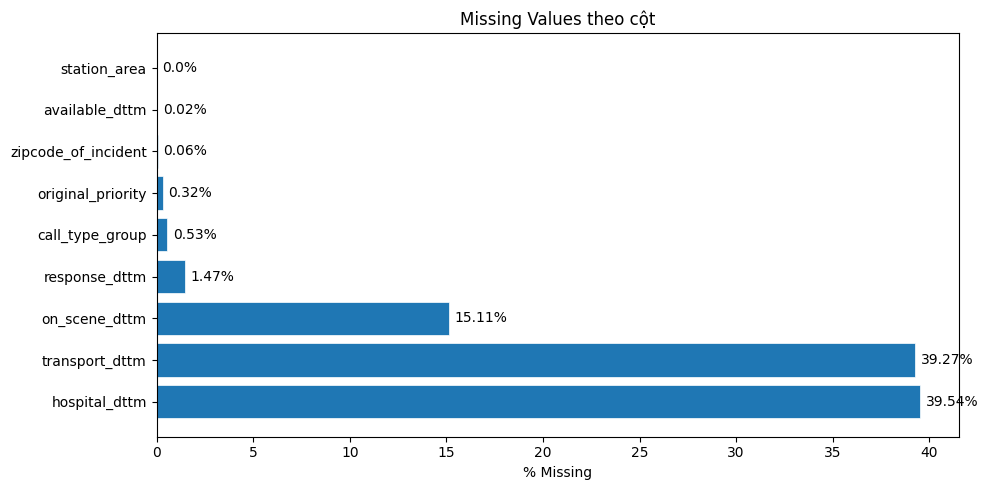

In [6]:
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values(
    "Missing %", ascending=False
)
print("Các cột có missing values:")
print(missing_df)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(
    missing_df.index,
    missing_df["Missing %"],
    edgecolor="white",
    linewidth=0.5,
)
ax.set_xlabel("% Missing")
ax.set_title("Missing Values theo cột")

for bar, pct in zip(bars, missing_df["Missing %"]):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{pct}%",
        va="center",
    )

plt.tight_layout()
plt.show()

In [7]:
unique_counts = df.select_dtypes(include=["object", "category"]).nunique()
print(unique_counts.to_frame(name="Unique Count"))

                        Unique Count
unit_id                          131
unit_type                          1
call_type                         30
call_type_group                    4
call_final_disposition            15
original_priority                  9
priority                           9
entry_dttm                    730528
response_dttm                 764198
on_scene_dttm                 658263
transport_dttm                471094
hospital_dttm                 469026
available_dttm                774268
battalion                         15
station_area                      98
data_as_of                       965


In [8]:
dup_count = df.duplicated(subset=["call_number"]).sum()
print(f"Duplicate theo call_number: {dup_count:,}")

Duplicate theo call_number: 44,953


# Data cleaning

In [9]:
transport_missing = (
    df.groupby("call_final_disposition")
    .agg(
        total=("transport_dttm", "size"),
        missing=("transport_dttm", lambda x: x.isnull().sum()),
    )
    .assign(pct_missing=lambda x: (x["missing"] / x["total"] * 100).round(1))
    .sort_values("pct_missing", ascending=False)
)
print(transport_missing)

                             total  missing  pct_missing
call_final_disposition                                  
No Merit                     27116    27038         99.7
Cancelled                    28811    28703         99.6
Unable to Locate             23156    23045         99.5
Medical Examiner             10514    10438         99.3
Duplicate                      227      225         99.1
Gone on Arrival               2299     2274         98.9
Fire                         19233    18979         98.7
Patient Declined Transport   44327    43433         98.0
Against Medical Advice       14177    13824         97.5
SFPD                          3517     3423         97.3
Other                       102020    97528         95.6
CHP                            102       56         54.9
Multi-casualty Incident        105       42         40.0
Code 3 Transport             40414     3193          7.9
Code 2 Transport            460580    32790          7.1


In [46]:
def timedelta_to_seconds(td_series):
    return td_series.dt.total_seconds()

time_cols = [
    "received_dttm",
    "entry_dttm",
    "dispatch_dttm",
    "response_dttm",
    "on_scene_dttm",
    "transport_dttm",
    "hospital_dttm",
    "available_dttm",
]

for col in time_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

df["dispatch_delay_sec"] = timedelta_to_seconds(
    df["dispatch_dttm"] - df["received_dttm"]
)
df["response_time_sec"] = timedelta_to_seconds(
    df["on_scene_dttm"] - df["received_dttm"]
)
df["travel_time_sec"] = timedelta_to_seconds(
    df["on_scene_dttm"] - df["response_dttm"]
)
df["transport_time_sec"] = timedelta_to_seconds(
    df["hospital_dttm"] - df["transport_dttm"]
)
df["total_busy_sec"] = timedelta_to_seconds(
    df["available_dttm"] - df["dispatch_dttm"]
)

time_features = [
    "dispatch_delay_sec",
    "response_time_sec",
    "travel_time_sec",
    "transport_time_sec",
    "total_busy_sec",
]
for c in time_features:
    df.loc[df[c] < 0, c] = np.nan

for c in ["dispatch_delay_sec", "response_time_sec", "travel_time_sec"]:
    df.loc[df[c] > 6 * 3600, c] = np.nan
    
for c in ["transport_time_sec", "total_busy_sec"]:
    df.loc[df[c] > 24 * 3600, c] = np.nan

n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Bỏ {n0 - len(df):,} dòng trùng hoàn toàn")

df["year"] = df["received_dttm"].dt.year
print(df[time_features].describe().round(1))

Bỏ 0 dòng trùng hoàn toàn
       dispatch_delay_sec  response_time_sec  travel_time_sec  \
count            776516.0           659155.0         659205.0   
mean                204.8              778.8            558.8   
std                 426.1              585.2            395.2   
min                   0.0                0.0              0.0   
25%                  70.0              440.0            293.0   
50%                 132.0              639.0            460.0   
75%                 207.0              970.0            737.0   
max               21496.0            20997.0          19886.0   

       transport_time_sec  total_busy_sec  
count            467571.0        775249.0  
mean                921.0          3830.2  
std                 575.3          2349.4  
min                   0.0             0.0  
25%                 504.0          1774.0  
50%                 816.0          4209.0  
75%                1230.0          5381.0  
max               44409.0         40

# EDA

**Theo thời gian**

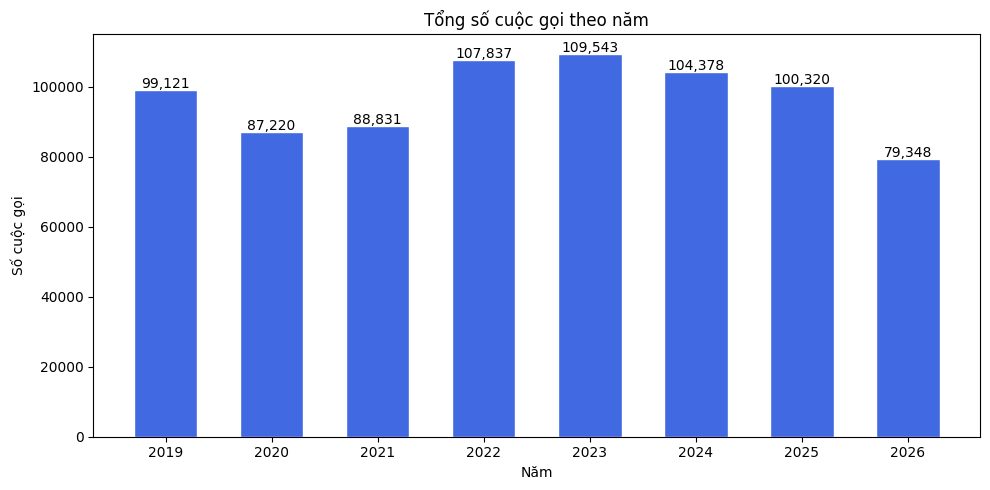

In [11]:
yearly = df.groupby("year").size().reset_index(name="calls")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(
    yearly["year"],
    yearly["calls"],
    color="royalblue",
    edgecolor="white",
    width=0.6,
)

for bar, val in zip(bars, yearly["calls"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 500,
        f"{val:,}",
        ha="center",
        fontsize=10,
    )

ax.set_xlabel("Năm")
ax.set_ylabel("Số cuộc gọi")
ax.set_title("Tổng số cuộc gọi theo năm")
ax.set_xticks(yearly["year"])

plt.tight_layout()
plt.show()

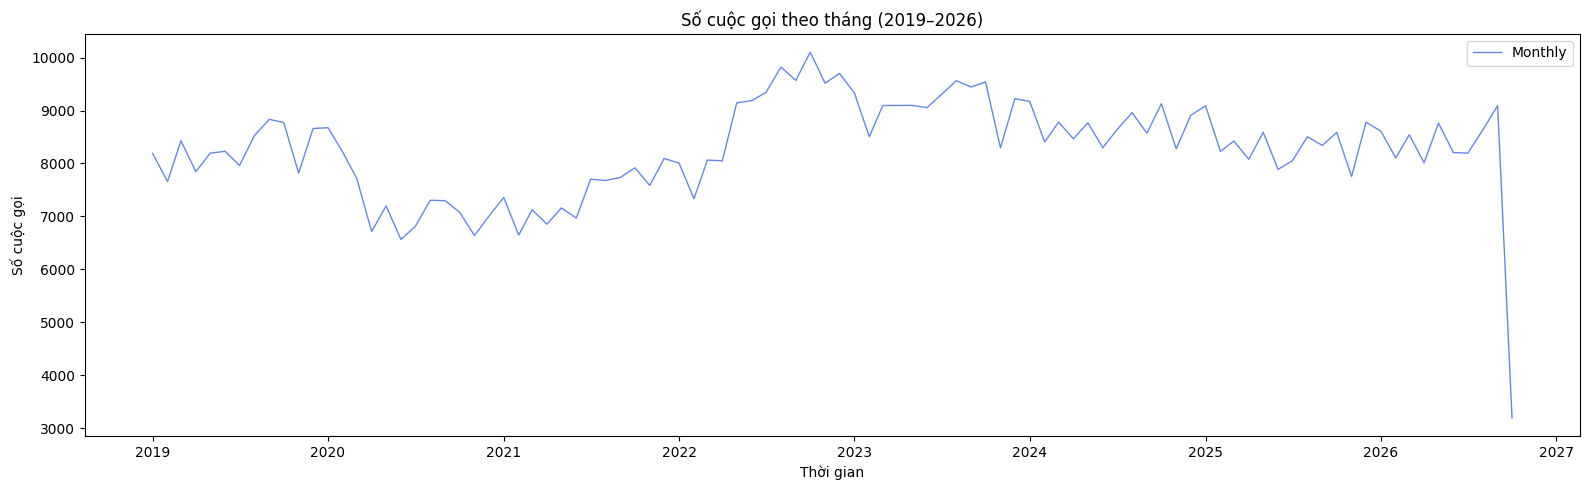

In [12]:
monthly = df.groupby(df["received_dttm"].dt.to_period("M")).size()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(
    monthly.index,
    monthly.values,
    color="royalblue",
    linewidth=1,
    alpha=0.8,
    label="Monthly",
)

ax.set_xlabel("Thời gian")
ax.set_ylabel("Số cuộc gọi")
ax.set_title("Số cuộc gọi theo tháng (2019–2026)")
ax.legend()

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

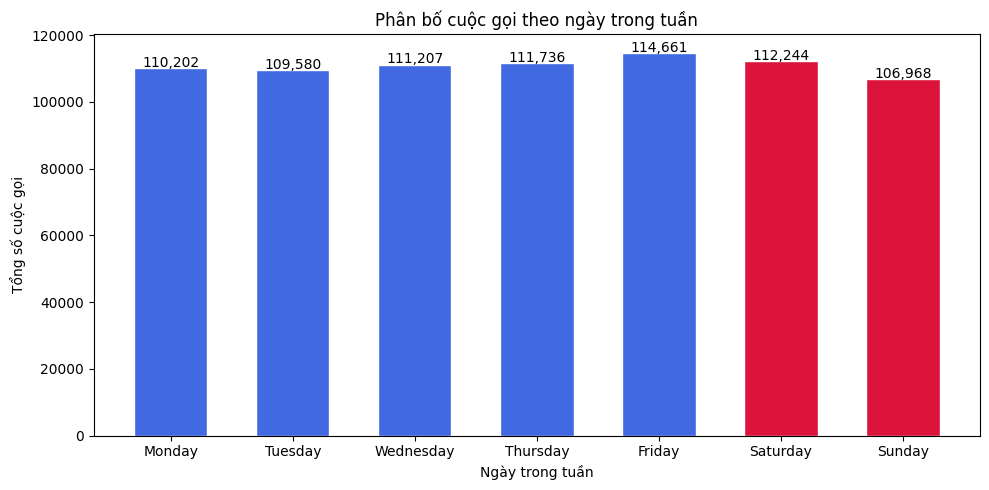

In [13]:
df["day_name"] = df["received_dttm"].dt.day_name()

dow_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
dow_counts = df["day_name"].value_counts().reindex(dow_order)

fig, ax = plt.subplots(figsize=(10, 5))
colors_dow = [
    "crimson" if d in ["Saturday", "Sunday"] else "royalblue" for d in dow_order
]
bars = ax.bar(
    dow_order,
    dow_counts.values,
    color=colors_dow,
    edgecolor="white",
    width=0.6,
)

for bar, val in zip(bars, dow_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 300,
        f"{val:,}",
        ha="center",
        fontsize=10,
    )

ax.set_xlabel("Ngày trong tuần")
ax.set_ylabel("Tổng số cuộc gọi")
ax.set_title("Phân bố cuộc gọi theo ngày trong tuần")

plt.tight_layout()
plt.show()

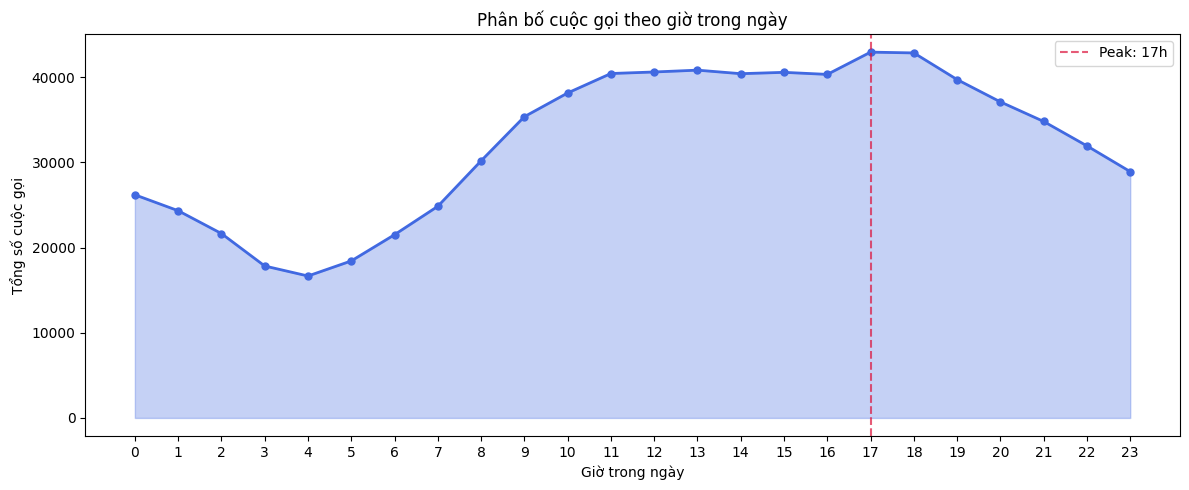

In [14]:
if "hour" not in df.columns:
    df["hour"] = df["received_dttm"].dt.hour

hourly = df.groupby("hour").size().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))

ax.fill_between(hourly.index, hourly.values, alpha=0.3, color="royalblue")

ax.plot(
    hourly.index,
    hourly.values,
    color="royalblue",
    linewidth=2,
    marker="o",
    markersize=5,
)

peak_hour = hourly.idxmax()
ax.axvline(
    peak_hour,
    color="crimson",
    linestyle="--",
    alpha=0.7,
    label=f"Peak: {peak_hour}h",
)

ax.set_xlabel("Giờ trong ngày")
ax.set_ylabel("Tổng số cuộc gọi")
ax.set_title("Phân bố cuộc gọi theo giờ trong ngày")
ax.set_xticks(range(24))
ax.legend()

plt.tight_layout()
plt.show()

**Theo phân loại cuộc gọi**

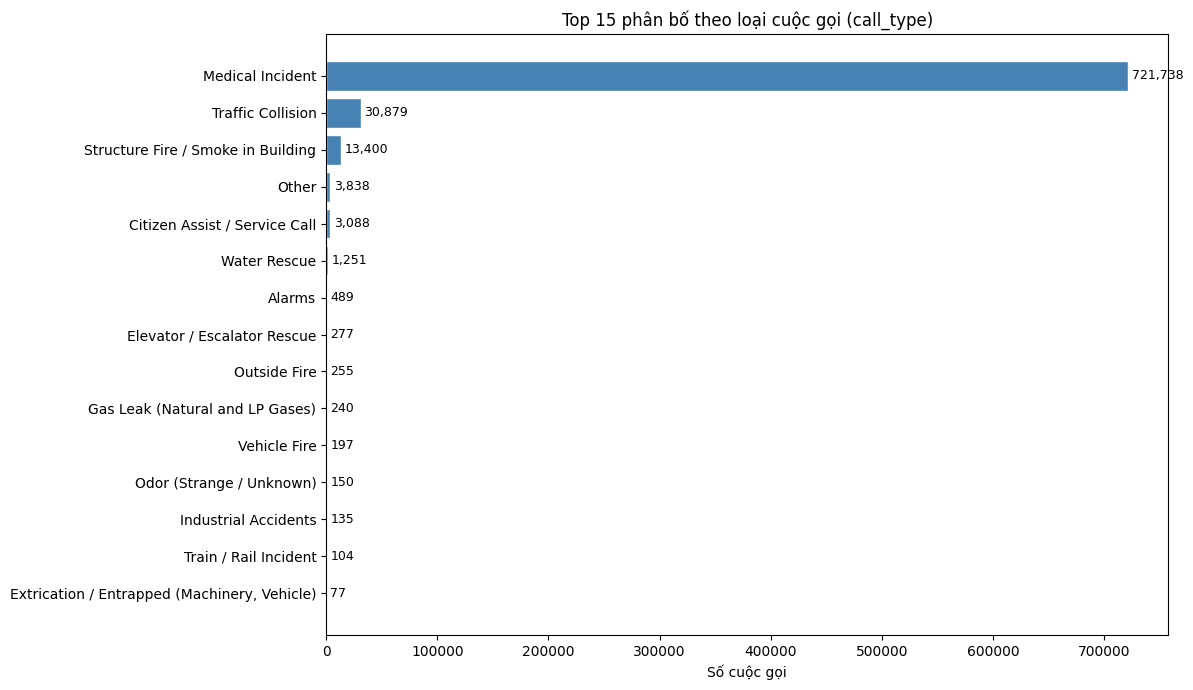

In [15]:
ct_counts = df["call_type"].value_counts()

top_n = 15
ct_counts_top = ct_counts.head(top_n)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    ct_counts_top.index[::-1],
    ct_counts_top.values[::-1],
    color="steelblue",
    edgecolor="white",
)

for bar, val in zip(bars, ct_counts_top.values[::-1]):
    ax.text(
        bar.get_width() + (ct_counts_top.max() * 0.005),
        bar.get_y() + bar.get_height() / 2,
        f"{val:,}",
        va="center",
        fontsize=9,
    )

ax.set_xlabel("Số cuộc gọi")
ax.set_title(f"Top {top_n} phân bố theo loại cuộc gọi (call_type)")

plt.tight_layout()
plt.show()

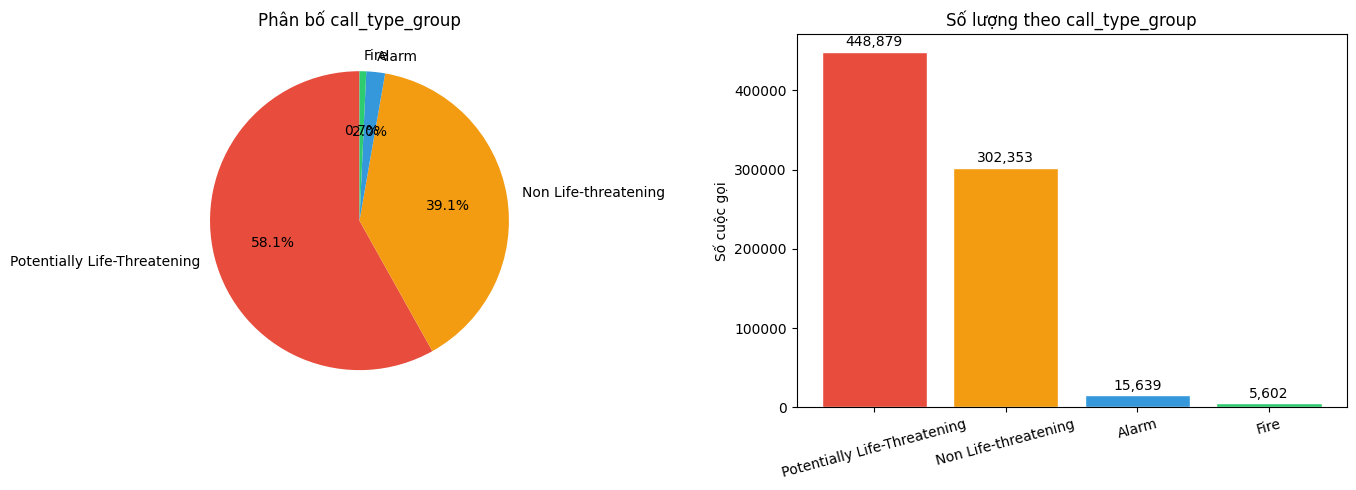

In [16]:
ctg_counts = df["call_type_group"].dropna().value_counts()

colors_pie = ["#e74c3c", "#f39c12", "#3498db", "#2ecc71", "#9b59b6", "#34495e"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

wedges, texts, autotexts = axes[0].pie(
    ctg_counts.values,
    labels=ctg_counts.index,
    autopct="%1.1f%%",
    colors=colors_pie[: len(ctg_counts)],
    startangle=90,
    textprops={"fontsize": 10},
)
axes[0].set_title("Phân bố call_type_group")

axes[1].bar(
    ctg_counts.index,
    ctg_counts.values,
    color=colors_pie[: len(ctg_counts)],
    edgecolor="white",
)

y_offset = ctg_counts.max() * 0.015
for i, (idx, val) in enumerate(ctg_counts.items()):
    axes[1].text(i, val + y_offset, f"{val:,}", ha="center", fontsize=10)

axes[1].set_ylabel("Số cuộc gọi")
axes[1].set_title("Số lượng theo call_type_group")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

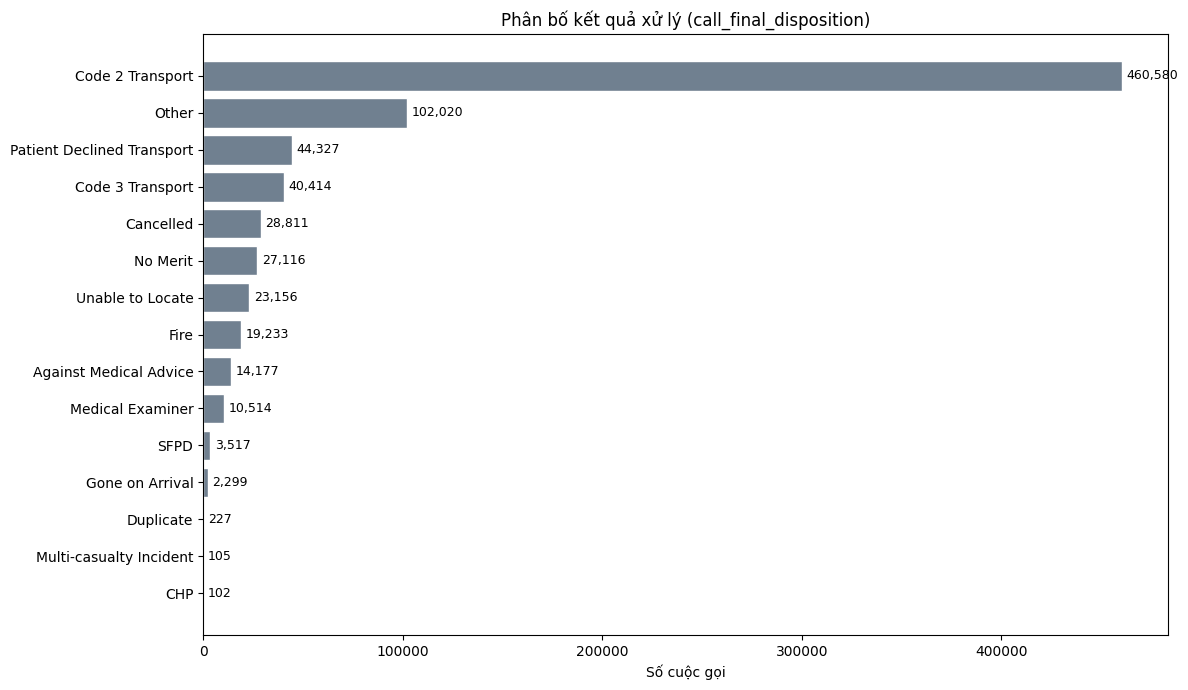

In [17]:
cfd_counts = df["call_final_disposition"].value_counts()
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    cfd_counts.index[::-1],
    cfd_counts.values[::-1],
    color="slategrey",
    edgecolor="white",
)

x_offset = cfd_counts.max() * 0.005

for bar, val in zip(bars, cfd_counts.values[::-1]):
    ax.text(
        bar.get_width() + x_offset,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,}",
        va="center",
        fontsize=9,
    )

ax.set_xlabel("Số cuộc gọi")
ax.set_title("Phân bố kết quả xử lý (call_final_disposition)")

plt.tight_layout()
plt.show()

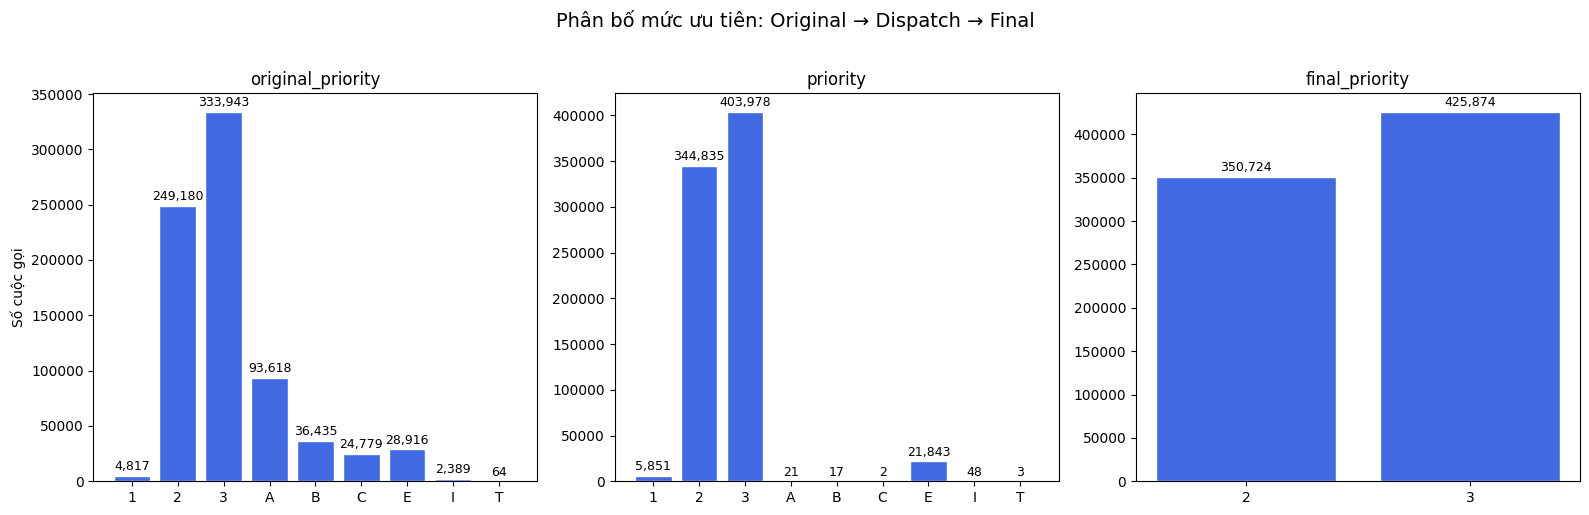

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(["original_priority", "priority", "final_priority"]):
    counts = df[col].dropna().value_counts().sort_index()

    axes[i].bar(
        counts.index.astype(str),
        counts.values,
        color="royalblue",
        edgecolor="white",
    )

    y_offset = counts.max() * 0.015

    for j, (idx, val) in enumerate(counts.items()):
        axes[i].text(
            j, val + y_offset, f"{val:,}", ha="center", fontsize=9
        )

    axes[i].set_title(col)
    axes[i].set_ylabel("Số cuộc gọi" if i == 0 else "")

plt.suptitle(
    "Phân bố mức ưu tiên: Original → Dispatch → Final", fontsize=14, y=1.02
)
plt.tight_layout()
plt.show()

In [47]:
orig = df["original_priority"].astype(str)
fin = df["final_priority"].astype(str)
num_mask = orig.isin(["1", "2", "3"])
df["priority_changed"] = np.where(num_mask, orig != fin, np.nan)
pct_changed = df.loc[num_mask, "priority_changed"].astype(float).mean() * 100
print(f"Tỷ lệ đổi priority (chỉ nhóm mã số 1/2/3, {num_mask.mean()*100:.1f}% dữ liệu): {pct_changed:.1f}%")

priority_transition = pd.crosstab(
    df["original_priority"], df["final_priority"], margins=True, normalize="index"
).round(3) * 100
print("Ma trận chuyển đổi priority (% theo hàng):")
print(priority_transition)

Tỷ lệ đổi priority (chỉ nhóm mã số 1/2/3, 75.7% dữ liệu): 9.1%
Ma trận chuyển đổi priority (% theo hàng):
final_priority        2     3
original_priority            
1                  95.1   4.9
2                  89.8  10.2
3                   6.9  93.1
A                  60.6  39.4
B                  64.0  36.0
C                  59.8  40.2
E                   5.9  94.1
I                  62.0  38.0
T                  73.4  26.6
All                45.2  54.8


Thời gian phản hồi

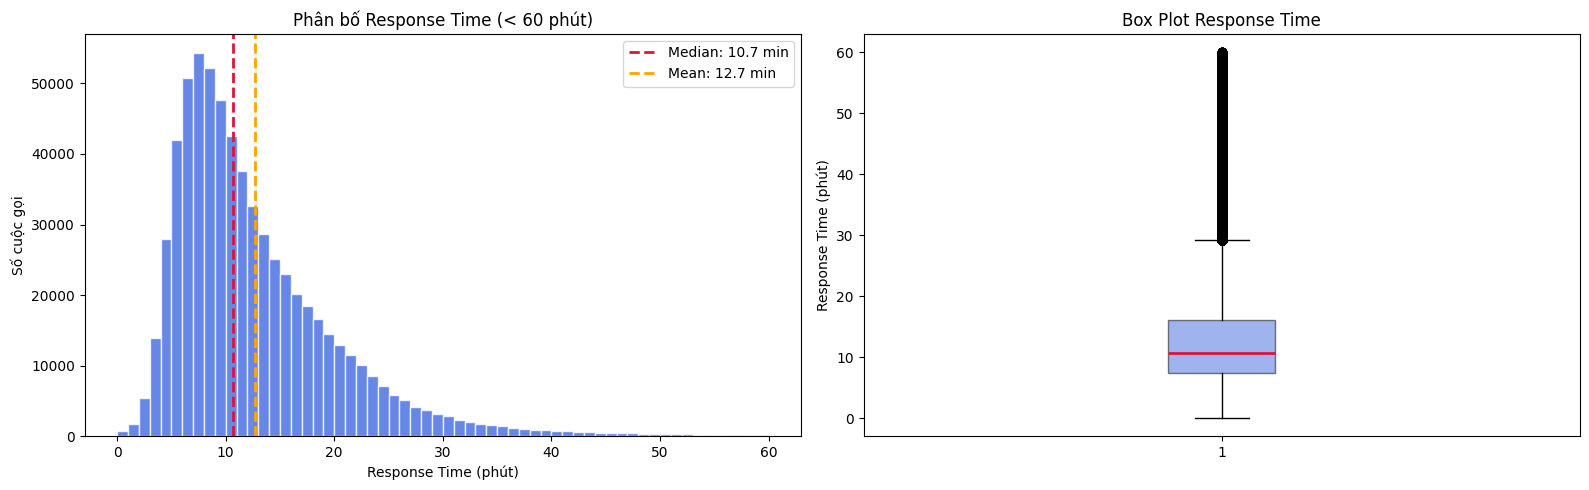

Response Time Stats (phút):
   Mean   : 12.7
   Median : 10.7
   P90    : 22.6
   P95    : 27.4
   P99    : 41.0


In [20]:
rt = df["response_time_sec"].dropna()
rt_valid = rt[(rt > 0) & (rt <= 3600)]
rt_minutes = rt_valid / 60
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(
    rt_minutes, bins=60, color="royalblue", edgecolor="white", alpha=0.8
)
axes[0].axvline(
    rt_minutes.median(),
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Median: {rt_minutes.median():.1f} min",
)
axes[0].axvline(
    rt_minutes.mean(),
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {rt_minutes.mean():.1f} min",
)
axes[0].set_xlabel("Response Time (phút)")
axes[0].set_ylabel("Số cuộc gọi")
axes[0].set_title("Phân bố Response Time (< 60 phút)")
axes[0].legend()

axes[1].boxplot(
    rt_minutes,
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="royalblue", alpha=0.5),
    medianprops=dict(color="crimson", linewidth=2),
)
axes[1].set_ylabel("Response Time (phút)")
axes[1].set_title("Box Plot Response Time")

plt.tight_layout()
plt.show()

print("Response Time Stats (phút):")
print(f"   Mean   : {rt_minutes.mean():.1f}")
print(f"   Median : {rt_minutes.median():.1f}")
print(f"   P90    : {rt_minutes.quantile(0.9):.1f}")
print(f"   P95    : {rt_minutes.quantile(0.95):.1f}")
print(f"   P99    : {rt_minutes.quantile(0.99):.1f}")

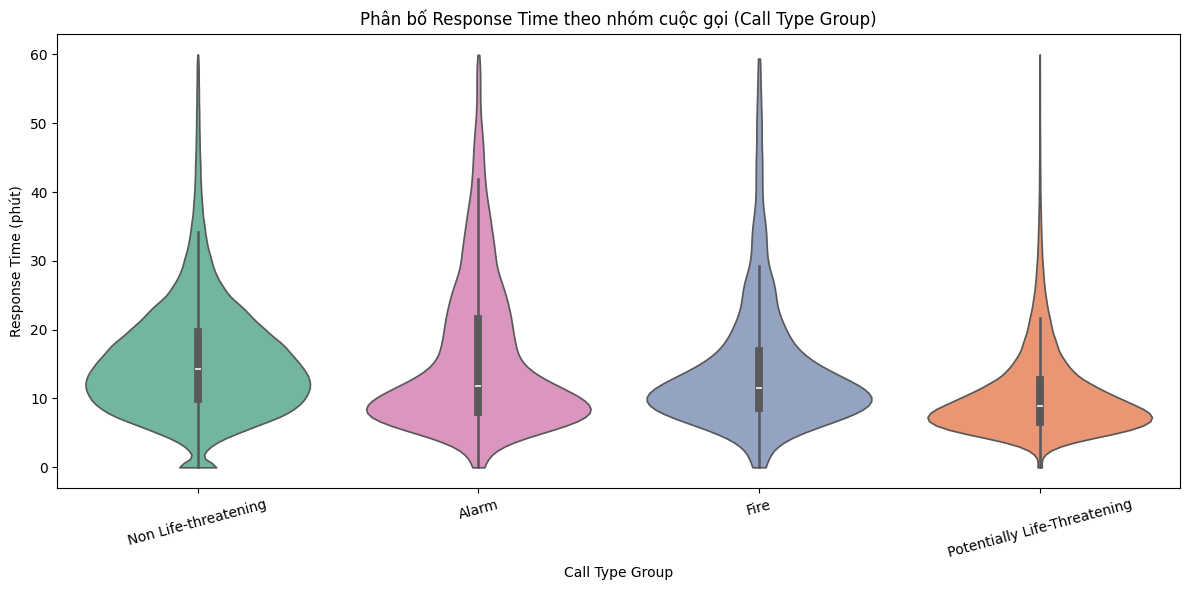

In [21]:
rt_data = df[df["response_time_sec"].between(0, 3600)].copy()
rt_data["rt_min"] = rt_data["response_time_sec"] / 60

rt_data = rt_data.dropna(subset=["call_type_group"])

groups_order = (
    rt_data.groupby("call_type_group")["rt_min"]
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(12, 6))

sns.violinplot(
    data=rt_data,
    x="call_type_group",
    y="rt_min",
    order=groups_order,
    hue="call_type_group",  
    palette="Set2",
    inner="box",  
    cut=0,  
    legend=False,
    ax=ax,
)

ax.set_xlabel("Call Type Group")
ax.set_ylabel("Response Time (phút)")
ax.set_title("Phân bố Response Time theo nhóm cuộc gọi (Call Type Group)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

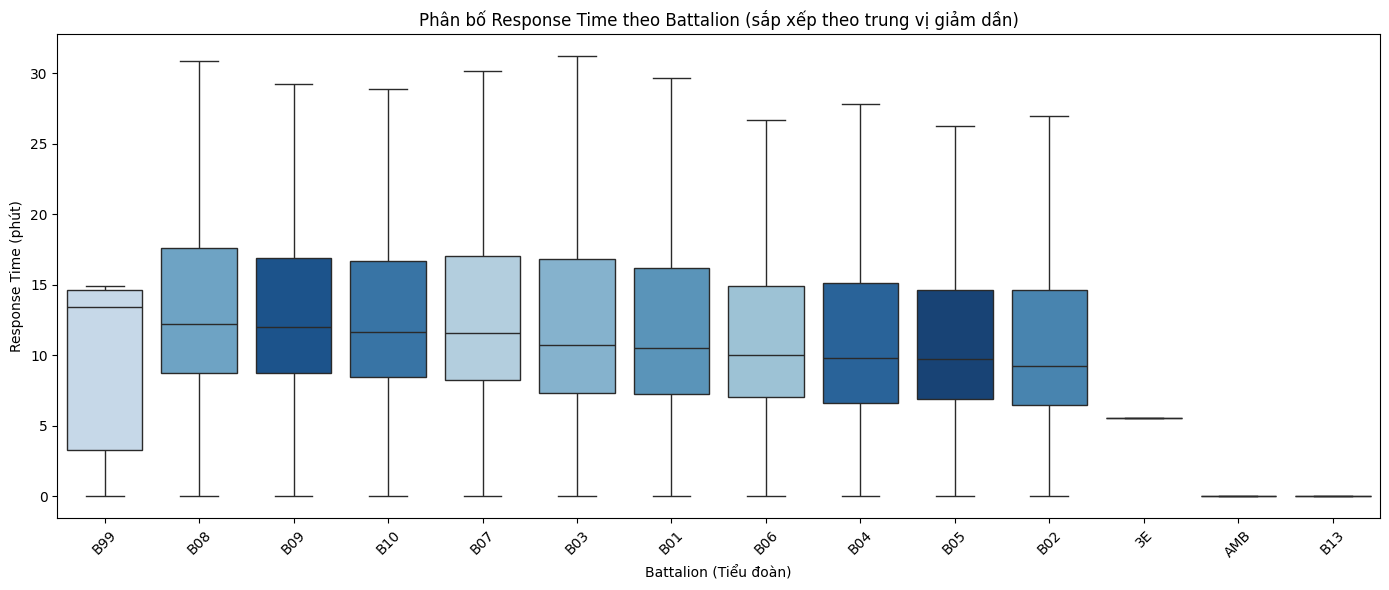

In [22]:
rt_data_clean = rt_data.dropna(subset=["battalion"]).copy()

battalion_order = (
    rt_data_clean.groupby("battalion")["rt_min"]
    .median()
    .sort_values(ascending=False)
    .index
)

fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(
    data=rt_data_clean,
    x="battalion",
    y="rt_min",
    order=battalion_order,
    hue="battalion",  
    palette="Blues_r", 
    showfliers=False,  
    legend=False,
    ax=ax,
)

ax.set_xlabel("Battalion (Tiểu đoàn)")
ax.set_ylabel("Response Time (phút)")
ax.set_title(
    "Phân bố Response Time theo Battalion (sắp xếp theo trung vị giảm dần)"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [49]:
if "hour" not in df.columns:
    df["hour"] = df["received_dttm"].dt.hour

# Chỉ xét các dòng có response_time hợp lệ (0-60 phút)
base = df[df["response_time_sec"].between(0, 3600)]
slow_threshold = 15 * 60
slow = base[base["response_time_sec"] > slow_threshold]

print(
    f"Response time > 15 phút: {len(slow):,} ({len(slow)/len(base)*100:.2f}% trên {len(base):,} dòng hợp lệ)"
)
print("\nSo sánh đặc điểm: Cuộc gọi chậm (>15m) vs. toàn bộ dòng hợp lệ\n")

ctg_slow = slow["call_type_group"].value_counts(normalize=True) * 100
ctg_all = base["call_type_group"].value_counts(normalize=True) * 100
df_ctg = (
    pd.DataFrame({"Slow (>15m) %": ctg_slow, "All valid %": ctg_all})
    .fillna(0)
    .round(2)
)
print("--- 1. Phân bố Call Type Group (%) ---")
print(df_ctg)
print("\n" + "=" * 50 + "\n")
bat_rate = (
    base.assign(is_slow=base["response_time_sec"] > slow_threshold)
    .groupby("battalion")["is_slow"]
    .agg(["mean", "size"])
    .rename(columns={"mean": "slow_rate", "size": "n"})
)
bat_rate["slow_rate"] = (bat_rate["slow_rate"] * 100).round(2)
print("--- 2. Top 5 Battalions có tỷ lệ đáp ứng chậm (%) ---")
print(bat_rate.sort_values("slow_rate", ascending=False).head(5))
print("\n" + "=" * 50 + "\n")

print("--- 3. Khung giờ trung bình tiếp nhận ---")
print(f"• Cuộc gọi chậm : {slow['hour'].mean():.1f}h")
print(f"• Tất cả (hợp lệ): {base['hour'].mean():.1f}h")
# ~15% dòng thiếu on_scene_dttm (chủ yếu cuộc gọi bị hủy/không có merit) nên kết luận chỉ áp dụng cho các cuộc gọi đã có xe đến hiện trường.")


Response time > 15 phút: 188,108 (28.66% trên 656,311 dòng hợp lệ)

So sánh đặc điểm: Cuộc gọi chậm (>15m) vs. toàn bộ dòng hợp lệ

--- 1. Phân bố Call Type Group (%) ---
                              Slow (>15m) %  All valid %
call_type_group                                         
Alarm                                  1.59         1.16
Fire                                   0.61         0.56
Non Life-threatening                  62.51        38.91
Potentially Life-Threatening          35.28        59.37


--- 2. Top 5 Battalions có tỷ lệ đáp ứng chậm (%) ---
           slow_rate       n
battalion                   
B08            35.23   51934
B09            32.82   55055
B07            32.56   29599
B10            31.53   59618
B03            31.22  120707


--- 3. Khung giờ trung bình tiếp nhận ---
• Cuộc gọi chậm : 12.7h
• Tất cả (hợp lệ): 12.7h


Theo địa lý

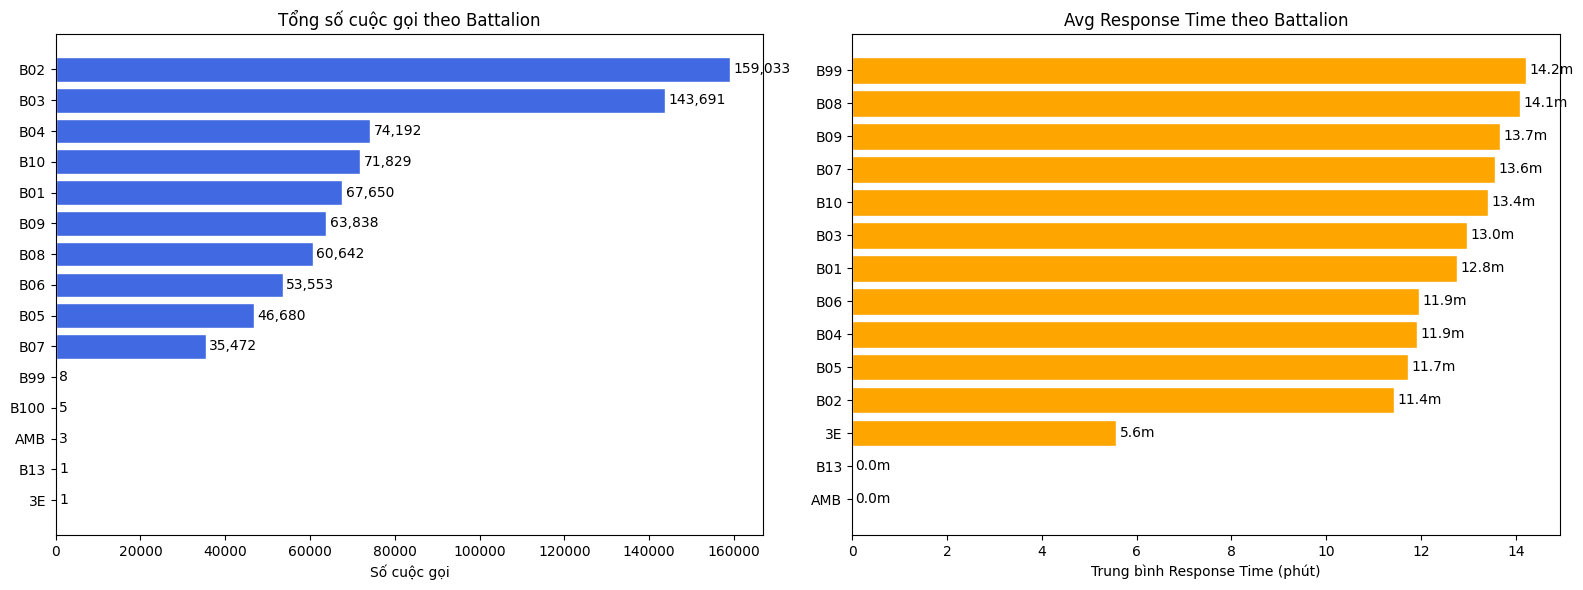

In [24]:
battalion_counts = (
    df["battalion"].dropna().value_counts().sort_values(ascending=True)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars = axes[0].barh(
    battalion_counts.index.astype(str),
    battalion_counts.values,
    color="royalblue",
    edgecolor="white",
)

x_offset1 = battalion_counts.max() * 0.005
for bar, val in zip(bars, battalion_counts.values):
    axes[0].text(
        bar.get_width() + x_offset1,
        bar.get_y() + bar.get_height() / 2,
        f"{val:,}",
        va="center",
        fontsize=10,
    )

axes[0].set_xlabel("Số cuộc gọi")
axes[0].set_title("Tổng số cuộc gọi theo Battalion")

rt_by_bn = (
    rt_data.dropna(subset=["battalion"])
    .groupby("battalion")["rt_min"]
    .mean()
    .sort_values(ascending=True)
)

bars2 = axes[1].barh(
    rt_by_bn.index.astype(str),
    rt_by_bn.values,
    color="orange",
    edgecolor="white",
)

x_offset2 = rt_by_bn.max() * 0.005
for bar, val in zip(bars2, rt_by_bn.values):
    axes[1].text(
        bar.get_width() + x_offset2,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}m",
        va="center",
        fontsize=10,
    )

axes[1].set_xlabel("Trung bình Response Time (phút)")
axes[1].set_title("Avg Response Time theo Battalion")

plt.tight_layout()
plt.show()

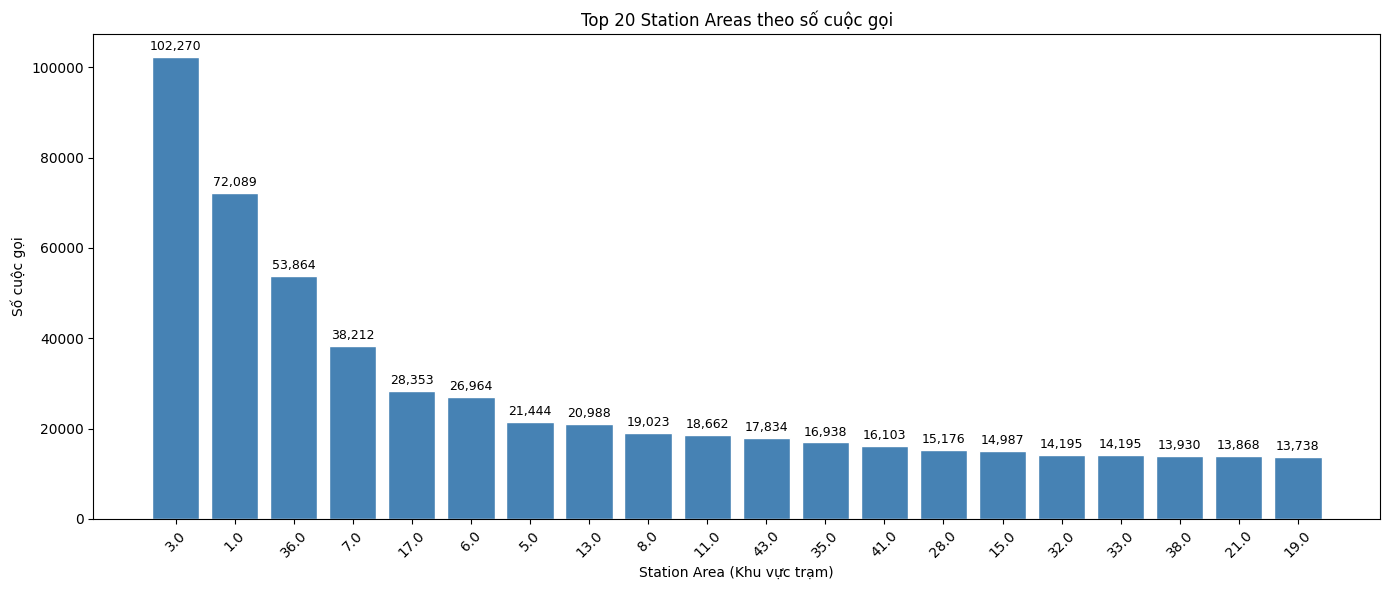

In [25]:
station_clean = df["station_area"].dropna()

station_clean = station_clean.apply(
    lambda x: str(int(x)) if isinstance(x, (int, float)) and pd.notnull(x) else str(x)
)

station_counts = station_clean.value_counts().head(20)

fig, ax = plt.subplots(figsize=(14, 6))

bars = ax.bar(
    station_counts.index,
    station_counts.values,
    color="steelblue",
    edgecolor="white",
)

y_offset = station_counts.max() * 0.015
for bar, val in zip(bars, station_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + y_offset,
        f"{val:,}",
        ha="center",
        fontsize=9,
    )

ax.set_xlabel("Station Area (Khu vực trạm)")
ax.set_ylabel("Số cuộc gọi")
ax.set_title("Top 20 Station Areas theo số cuộc gọi")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

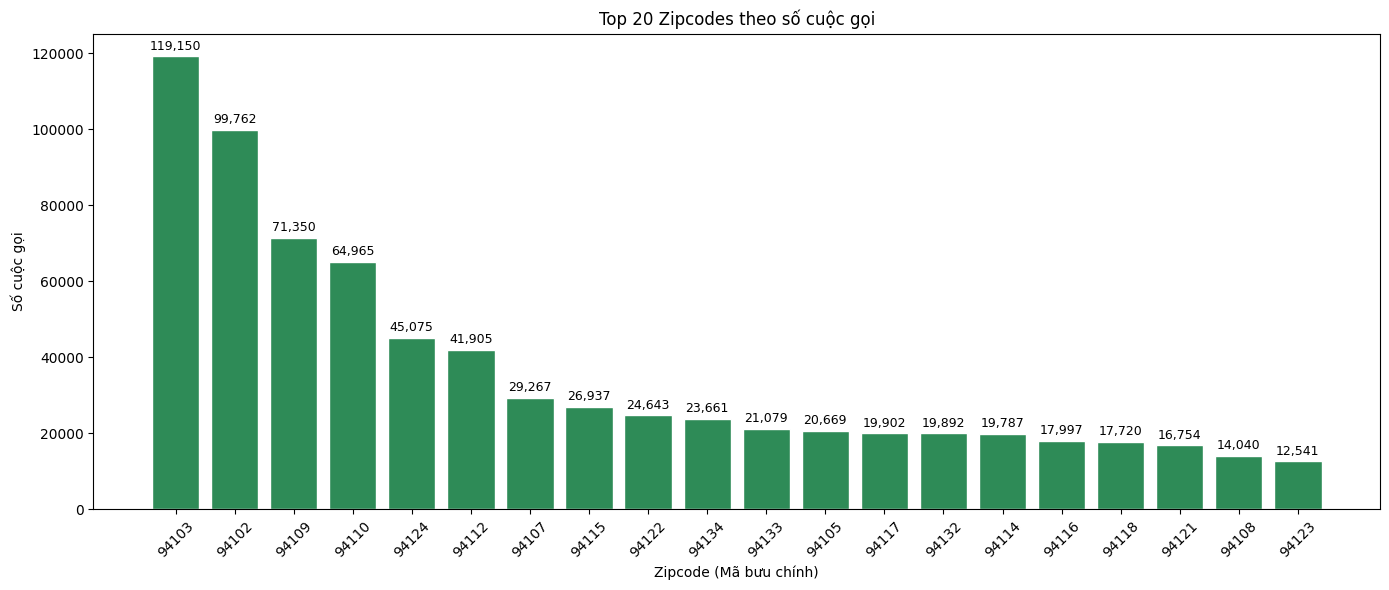

In [26]:
zip_clean = df["zipcode_of_incident"].dropna()

zip_clean = zip_clean.apply(
    lambda x: (
        str(int(x)) if isinstance(x, (int, float)) and pd.notnull(x) else str(x)
    )
)

zip_counts = zip_clean.value_counts().head(20)

fig, ax = plt.subplots(figsize=(14, 6))

bars = ax.bar(
    zip_counts.index,
    zip_counts.values,
    color="seagreen",
    edgecolor="white",
)

y_offset = zip_counts.max() * 0.015
for bar, val in zip(bars, zip_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + y_offset,
        f"{val:,}",
        ha="center",
        fontsize=9,
    )

ax.set_xlabel("Zipcode (Mã bưu chính)")
ax.set_ylabel("Số cuộc gọi")
ax.set_title("Top 20 Zipcodes theo số cuộc gọi")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Feature Engineering

**Định nghĩa target & phạm vi dự báo**

- `call_count` = số **cuộc gọi duy nhất** (`call_number`) nhận được mỗi giờ (theo `received_dttm`)
- Nhu cầu về năng lực được mô tả thêm bởi `n_units_dispatched` (số xe) và `total_busy_hours` (khối lượng công việc) 

In [50]:
df["was_transported"] = df["transport_dttm"].notna()  # tránh str.contains("Transport") khớp nhầm "Declined Transport"

calls = (
    df.groupby("call_number")
    .agg(
        received_dttm=("received_dttm", "min"),
        incident_number=("incident_number", "first"),
        call_type_group=("call_type_group", "first"),
        was_transported=("was_transported", "any"),
        response_time_sec=("response_time_sec", "min"),  # xe đến sớm nhất
        n_units=("unit_id", "size"),
        busy_sec=("total_busy_sec", "sum"),
    )
    .reset_index()
)
calls["hour_bucket"] = calls["received_dttm"].dt.floor("h")
calls["is_lt"] = calls["call_type_group"] == "Potentially Life-Threatening"
calls["is_nlt"] = calls["call_type_group"] == "Non Life-threatening"
calls["is_fire"] = calls["call_type_group"] == "Fire"
calls["is_alarm"] = calls["call_type_group"] == "Alarm"
print(f"{len(df):,} dòng điều động -> {len(calls):,} cuộc gọi duy nhất")

hourly_calls = (
    calls.groupby("hour_bucket")
    .agg(
        call_count=("call_number", "size"),               # TARGET: số cuộc gọi / giờ
        n_life_threatening=("is_lt", "sum"),
        n_non_life_threatening=("is_nlt", "sum"),
        n_fire=("is_fire", "sum"),
        n_alarm=("is_alarm", "sum"),
        n_transported=("was_transported", "sum"),
        n_units_dispatched=("n_units", "sum"),            # số xe điều động
        n_incidents=("incident_number", "nunique"),
        total_busy_hours=("busy_sec", lambda x: x.sum() / 3600),  # khối lượng công việc
        avg_response_time=("response_time_sec", "mean"),
        median_response_time=("response_time_sec", "median"),
    )
    .reset_index()
)

full_range = pd.date_range(
    start=hourly_calls["hour_bucket"].min(),
    end=hourly_calls["hour_bucket"].max(),
    freq="h",
)
hourly_calls = hourly_calls.set_index("hour_bucket").reindex(full_range)
hourly_calls.index.name = "hour_bucket"

count_cols = [
    "call_count", "n_life_threatening", "n_non_life_threatening", "n_fire",
    "n_alarm", "n_transported", "n_units_dispatched", "n_incidents",
]
n_missing_hours = hourly_calls["call_count"].isna().sum()
hourly_calls[count_cols] = hourly_calls[count_cols].fillna(0).astype(int)
hourly_calls["total_busy_hours"] = hourly_calls["total_busy_hours"].fillna(0)
hourly_calls = hourly_calls.reset_index()

# Bỏ giờ cuối vì có thể chưa đủ dữ liệu
hourly_calls = hourly_calls.iloc[:-1].reset_index(drop=True)

print(f"Giờ không có cuộc gọi nào (điền 0): {n_missing_hours}")
print(f"Hourly dataset: {hourly_calls.shape[0]:,} dòng × {hourly_calls.shape[1]} cột")
print(f"   Từ {hourly_calls['hour_bucket'].min()} → {hourly_calls['hour_bucket'].max()}")
print("\nTarget (call_count = số cuộc gọi duy nhất / giờ):")
print(hourly_calls["call_count"].describe())
print(f"Var/Mean = {hourly_calls['call_count'].var()/hourly_calls['call_count'].mean():.2f} (>1: overdispersion, cân nhắc loss Poisson/NegBin)")

hourly_calls.head(10)


776,598 dòng điều động -> 731,645 cuộc gọi duy nhất
Giờ không có cuộc gọi nào (điền 0): 90
Hourly dataset: 68,163 dòng × 12 cột
   Từ 2019-01-01 00:00:00 → 2026-10-11 02:00:00

Target (call_count = số cuộc gọi duy nhất / giờ):
count    68163.000000
mean        10.733697
std          4.676162
min          0.000000
25%          7.000000
50%         10.000000
75%         14.000000
max         44.000000
Name: call_count, dtype: float64
Var/Mean = 2.04 (>1: overdispersion, cân nhắc loss Poisson/NegBin)


,hour_bucket,call_count,n_life_threatening,n_non_life_threatening,n_fire,n_alarm,n_transported,n_units_dispatched,n_incidents,total_busy_hours,avg_response_time,median_response_time
0,2019-01-01 00:00:00,14,11,2,1,0,11,17,14,14.698611,563.153846,463.0
1,2019-01-01 01:00:00,14,7,7,0,0,10,14,14,12.595278,649.857143,547.5
2,2019-01-01 02:00:00,18,11,7,0,0,14,18,18,16.538333,538.571429,532.5
3,2019-01-01 03:00:00,7,5,2,0,0,7,7,7,7.357778,766.428571,612.0
4,2019-01-01 04:00:00,9,2,7,0,0,5,10,9,6.760556,735.428571,701.0
5,2019-01-01 05:00:00,11,4,7,0,0,8,11,11,9.777500,699.555556,682.0
6,2019-01-01 06:00:00,7,3,2,0,2,4,10,7,5.042778,711.750000,630.5
7,2019-01-01 07:00:00,9,7,2,0,0,8,9,9,11.066389,489.444444,467.0
8,2019-01-01 08:00:00,5,2,3,0,0,4,5,5,5.619444,874.200000,926.0
9,2019-01-01 09:00:00,11,9,2,0,0,9,11,11,12.391111,441.100000,462.5


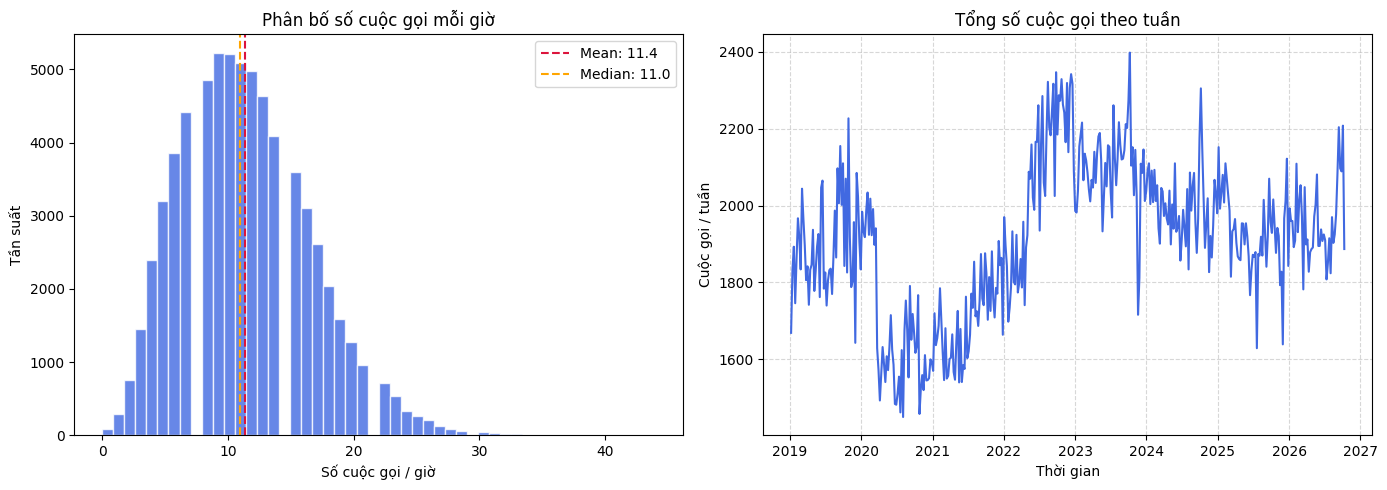

In [28]:
if not pd.api.types.is_datetime64_any_dtype(hourly_calls["hour_bucket"]):
    hourly_calls["hour_bucket"] = pd.to_datetime(hourly_calls["hour_bucket"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    hourly_calls["call_count"],
    bins=50,
    color="royalblue",
    edgecolor="white",
    alpha=0.8,
)
axes[0].set_xlabel("Số cuộc gọi / giờ")
axes[0].set_ylabel("Tần suất")
axes[0].set_title("Phân bố số cuộc gọi mỗi giờ")

mean_val = hourly_calls["call_count"].mean()
median_val = hourly_calls["call_count"].median()

axes[0].axvline(
    mean_val,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.1f}",
)
axes[0].axvline(
    median_val,
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label=f"Median: {median_val:.1f}",
)
axes[0].legend()

weekly_target = (
    hourly_calls.set_index("hour_bucket")["call_count"].resample("W").sum()
)

axes[1].plot(
    weekly_target.index, weekly_target.values, color="royalblue", linewidth=1.5
)
axes[1].set_xlabel("Thời gian")
axes[1].set_ylabel("Cuộc gọi / tuần")
axes[1].set_title("Tổng số cuộc gọi theo tuần")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [51]:
ts = hourly_calls.copy()

if not pd.api.types.is_datetime64_any_dtype(ts["hour_bucket"]):
    ts["hour_bucket"] = pd.to_datetime(ts["hour_bucket"])

ts["hour"] = ts["hour_bucket"].dt.hour
ts["day_of_week"] = ts["hour_bucket"].dt.dayofweek
ts["month"] = ts["hour_bucket"].dt.month
ts["year"] = ts["hour_bucket"].dt.year
ts["day_of_month"] = ts["hour_bucket"].dt.day
ts["week_of_year"] = ts["hour_bucket"].dt.isocalendar().week.astype(int)
ts["quarter"] = ts["hour_bucket"].dt.quarter
ts["is_weekend"] = ts["day_of_week"].isin([5, 6]).astype(int)

ts["sin_hour"] = np.sin(2 * np.pi * ts["hour"] / 24)
ts["cos_hour"] = np.cos(2 * np.pi * ts["hour"] / 24)
ts["sin_dow"] = np.sin(2 * np.pi * ts["day_of_week"] / 7)
ts["cos_dow"] = np.cos(2 * np.pi * ts["day_of_week"] / 7)
ts["sin_month"] = np.sin(2 * np.pi * (ts["month"] - 1) / 12)
ts["cos_month"] = np.cos(2 * np.pi * (ts["month"] - 1) / 12)

from pandas.tseries.holiday import USFederalHolidayCalendar
_hol = USFederalHolidayCalendar().holidays(start=ts["hour_bucket"].min().normalize(),
                                           end=ts["hour_bucket"].max().normalize())
ts["is_holiday"] = ts["hour_bucket"].dt.normalize().isin(_hol).astype(int)
# Giai đoạn COVID (SF shelter-in-place 16/03/2020 -> mở cửa lại 15/06/2021)
ts["is_covid_period"] = ts["hour_bucket"].between("2020-03-16", "2021-06-15").astype(int)

print(f"Calendar + Cyclical features: {ts.shape[1]} cột")
ts[
    [
        "hour_bucket",
        "hour",
        "day_of_week",
        "month",
        "is_weekend",
        "sin_hour",
        "cos_hour",
    ]
].head(10)

Calendar + Cyclical features: 28 cột


,hour_bucket,hour,day_of_week,month,is_weekend,sin_hour,cos_hour
0,2019-01-01 00:00:00,0,1,1,0,0.000000,1.000000e+00
1,2019-01-01 01:00:00,1,1,1,0,0.258819,9.659258e-01
2,2019-01-01 02:00:00,2,1,1,0,0.500000,8.660254e-01
3,2019-01-01 03:00:00,3,1,1,0,0.707107,7.071068e-01
4,2019-01-01 04:00:00,4,1,1,0,0.866025,5.000000e-01
5,2019-01-01 05:00:00,5,1,1,0,0.965926,2.588190e-01
6,2019-01-01 06:00:00,6,1,1,0,1.000000,6.123234e-17
7,2019-01-01 07:00:00,7,1,1,0,0.965926,-2.588190e-01
8,2019-01-01 08:00:00,8,1,1,0,0.866025,-5.000000e-01
9,2019-01-01 09:00:00,9,1,1,0,0.707107,-7.071068e-01


In [52]:
rolling_windows = [6, 12, 24, 48, 168] 

for window in rolling_windows:
    ts[f"rolling_mean_{window}h"] = (
        ts["call_count"].shift(1).rolling(window, min_periods=1).mean()
    )
    ts[f"rolling_std_{window}h"] = (
        ts["call_count"]
        .shift(1)
        .rolling(window, min_periods=1)
        .std()
        .fillna(0)  
    )

ts["ewm_24h"] = ts["call_count"].shift(1).ewm(span=24, adjust=False).mean()
ts["ewm_168h"] = ts["call_count"].shift(1).ewm(span=168, adjust=False).mean()

print("Rolling + EWM features:")
print(f"   • Tổng số cột hiện tại: {ts.shape[1]}")
print(f"   • Số lượng giá trị thiếu (NaN) còn lại trong tập dữ liệu: {ts.isna().sum().sum()}")

new_cols = [col for col in ts.columns if "rolling" in col or "ewm" in col]
ts[["hour_bucket", "call_count"] + new_cols[:4]].head(10)

Rolling + EWM features:
   • Tổng số cột hiện tại: 40
   • Số lượng giá trị thiếu (NaN) còn lại trong tập dữ liệu: 255


,hour_bucket,call_count,rolling_mean_6h,rolling_std_6h,rolling_mean_12h,rolling_std_12h
0,2019-01-01 00:00:00,14,NaN,0.000000,NaN,0.000000
1,2019-01-01 01:00:00,14,14.000000,0.000000,14.000000,0.000000
2,2019-01-01 02:00:00,18,14.000000,0.000000,14.000000,0.000000
3,2019-01-01 03:00:00,7,15.333333,2.309401,15.333333,2.309401
4,2019-01-01 04:00:00,9,13.250000,4.573474,13.250000,4.573474
5,2019-01-01 05:00:00,11,12.400000,4.393177,12.400000,4.393177
6,2019-01-01 06:00:00,7,12.166667,3.970726,12.166667,3.970726
7,2019-01-01 07:00:00,9,11.000000,4.335897,11.428571,4.117327
8,2019-01-01 08:00:00,5,10.166667,4.119061,11.125000,3.907411
9,2019-01-01 09:00:00,11,8.000000,2.097618,10.444444,4.186619


In [31]:
lag_hours = [1, 2, 3, 6, 12, 24, 48, 168] 

for lag in lag_hours:
    ts[f"lag_{lag}h"] = ts["call_count"].shift(lag)

print(f"Lag features: {len(lag_hours)} lags")
ts[["hour_bucket", "call_count"] + [f"lag_{l}h" for l in lag_hours]].head(170)

Lag features: 8 lags


,hour_bucket,call_count,lag_1h,lag_2h,lag_3h,lag_6h,lag_12h,lag_24h,lag_48h,lag_168h
0,2019-01-01 00:00:00,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2019-01-01 01:00:00,14,17.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2019-01-01 02:00:00,18,14.0,17.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2019-01-01 03:00:00,7,18.0,14.0,17.0,NaN,NaN,NaN,NaN,NaN
4,2019-01-01 04:00:00,10,7.0,18.0,14.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
165,2019-01-07 21:00:00,10,13.0,12.0,17.0,17.0,25.0,16.0,16.0,NaN
166,2019-01-07 22:00:00,8,10.0,13.0,12.0,20.0,13.0,14.0,14.0,NaN
167,2019-01-07 23:00:00,7,8.0,10.0,13.0,13.0,12.0,11.0,7.0,NaN
168,2019-01-08 00:00:00,9,7.0,8.0,10.0,17.0,9.0,4.0,10.0,17.0


In [53]:
print("=" * 60)
print("TẤT CẢ FEATURES TRONG DATASET TIME-SERIES:")
print("=" * 60)

feature_groups = {
    "Target": ["call_count"],
    "Sub-targets": ["n_life_threatening", "n_non_life_threatening", "n_fire", "n_alarm", "n_transported", "n_units_dispatched"],
    "Aggregated stats": ["avg_response_time", "median_response_time"],
    "Calendar": ["hour", "day_of_week", "month", "year", "day_of_month", "week_of_year", "quarter", "is_weekend", "is_holiday"],
    "Cyclical": ["sin_hour", "cos_hour", "sin_dow", "cos_dow", "sin_month", "cos_month"],
    "Lag": [c for c in ts.columns if c.startswith("lag_")],
    "Rolling": [c for c in ts.columns if c.startswith("rolling_")],
    "EWM": [c for c in ts.columns if c.startswith("ewm_")],
}

for group, cols in feature_groups.items():
    existing = [c for c in cols if c in ts.columns]
    print(f"\n{group} ({len(existing)} features):")
    for c in existing:
        print(f"   - {c}")

print(f"\nTổng: {ts.shape[1]} cột (bao gồm hour_bucket)")

TẤT CẢ FEATURES TRONG DATASET TIME-SERIES:

Target (1 features):
   - call_count

Sub-targets (6 features):
   - n_life_threatening
   - n_non_life_threatening
   - n_fire
   - n_alarm
   - n_transported
   - n_units_dispatched

Aggregated stats (2 features):
   - avg_response_time
   - median_response_time

Calendar (9 features):
   - hour
   - day_of_week
   - month
   - year
   - day_of_month
   - week_of_year
   - quarter
   - is_weekend
   - is_holiday

Cyclical (6 features):
   - sin_hour
   - cos_hour
   - sin_dow
   - cos_dow
   - sin_month
   - cos_month

Lag (0 features):

Rolling (10 features):
   - rolling_mean_6h
   - rolling_std_6h
   - rolling_mean_12h
   - rolling_std_12h
   - rolling_mean_24h
   - rolling_std_24h
   - rolling_mean_48h
   - rolling_std_48h
   - rolling_mean_168h
   - rolling_std_168h

EWM (2 features):
   - ewm_24h
   - ewm_168h

Tổng: 40 cột (bao gồm hour_bucket)


# Train / Validation / Test split

In [33]:
max_lag = max(lag_hours)  # 168 = 7 ngày
ts_clean = ts.iloc[max_lag:].copy().reset_index(drop=True)
print(f"Loại bỏ {max_lag} dòng đầu (NaN từ lag) → còn {ts_clean.shape[0]:,} dòng")

Loại bỏ 168 dòng đầu (NaN từ lag) → còn 67,996 dòng


In [54]:
TRAIN_END = "2024-12-31 23:00:00"
VAL_END = "2025-12-31 23:00:00"

train = ts_clean[ts_clean["hour_bucket"] <= TRAIN_END].copy()
val = ts_clean[(ts_clean["hour_bucket"] > TRAIN_END) & (ts_clean["hour_bucket"] <= VAL_END)].copy()
test = ts_clean[ts_clean["hour_bucket"] > VAL_END].copy()

print("=" * 60)
print("DATA SPLIT SUMMARY:")
print("=" * 60)
for name, subset in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"\n{name}:")
    print(f"   Rows      : {subset.shape[0]:,}")
    print(f"   Period    : {subset['hour_bucket'].min()} → {subset['hour_bucket'].max()}")
    print(f"   % of total: {subset.shape[0]/ts_clean.shape[0]*100:.1f}%")
    print(f"   Avg calls : {subset['call_count'].mean():.1f}")
    print(f"   Std calls : {subset['call_count'].std():.1f}")

DATA SPLIT SUMMARY:

Train:
   Rows      : 52,440
   Period    : 2019-01-08 00:00:00 → 2024-12-31 23:00:00
   % of total: 77.1%
   Avg calls : 11.3
   Std calls : 5.1

Validation:
   Rows      : 8,760
   Period    : 2025-01-01 00:00:00 → 2025-12-31 23:00:00
   % of total: 12.9%
   Avg calls : 11.5
   Std calls : 5.2

Test:
   Rows      : 6,796
   Period    : 2026-01-01 00:00:00 → 2026-10-11 03:00:00
   % of total: 10.0%
   Avg calls : 11.7
   Std calls : 5.0


In [56]:
exclude_cols = [
    "hour_bucket", "call_count",
    "n_life_threatening", "n_non_life_threatening", "n_fire", "n_alarm",
    "n_transported", "n_units_dispatched",
    "avg_response_time", "median_response_time",
    "n_incidents", "total_busy_hours",
    "year", 
]
feature_cols = [c for c in ts_clean.columns if c not in exclude_cols]

X_train, y_train = train[feature_cols], train["call_count"]
X_val, y_val = val[feature_cols], val["call_count"]
X_test, y_test = test[feature_cols], test["call_count"]

print("=" * 60)
print("FINAL DATASETS:")
print("=" * 60)
print(f"\nFeatures: {len(feature_cols)} cột")
print(f"   {feature_cols}")
print(f"\nX_train : {X_train.shape}")
print(f"y_train : {y_train.shape} | mean={y_train.mean():.1f}")
print(f"X_val   : {X_val.shape}")
print(f"y_val   : {y_val.shape} | mean={y_val.mean():.1f}")
print(f"X_test  : {X_test.shape}")
print(f"y_test  : {y_test.shape} | mean={y_test.mean():.1f}")
# Baseline để so sánh mô hình sau này
def mae(a, b): return float(np.mean(np.abs(a - b)))
hod_dow = train.groupby(["hour", "day_of_week"])["call_count"].mean()
for name, d in [("Val", val), ("Test", test)]:
    naive168 = d["lag_168h"]
    prof = d.set_index(["hour", "day_of_week"]).index.map(hod_dow).to_numpy()
    print(f"{name}: MAE seasonal-naive(168h) = {mae(d['call_count'], naive168):.2f} | "
          f"MAE trung bình giờ×thứ = {mae(d['call_count'].to_numpy(), prof):.2f}")


FINAL DATASETS:

Features: 33 cột
   ['hour', 'day_of_week', 'month', 'day_of_month', 'week_of_year', 'quarter', 'is_weekend', 'sin_hour', 'cos_hour', 'sin_dow', 'cos_dow', 'sin_month', 'cos_month', 'rolling_mean_6h', 'rolling_std_6h', 'rolling_mean_12h', 'rolling_std_12h', 'rolling_mean_24h', 'rolling_std_24h', 'rolling_mean_48h', 'rolling_std_48h', 'rolling_mean_168h', 'rolling_std_168h', 'ewm_24h', 'ewm_168h', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'lag_24h', 'lag_48h', 'lag_168h']

X_train : (52440, 33)
y_train : (52440,) | mean=11.3
X_val   : (8760, 33)
y_val   : (8760,) | mean=11.5
X_test  : (6796, 33)
y_test  : (6796,) | mean=11.7
Val: MAE seasonal-naive(168h) = 4.18 | MAE trung bình giờ×thứ = 3.08
Test: MAE seasonal-naive(168h) = 4.11 | MAE trung bình giờ×thứ = 3.02


In [57]:
output_dir = "./data_processed"
os.makedirs(output_dir, exist_ok=True)
for name, d in [("train", train), ("val", val), ("test", test)]:
    d[["hour_bucket"] + feature_cols].to_csv(f"{output_dir}/X_{name}.csv", index=False)
    d[["hour_bucket", "call_count"]].to_csv(f"{output_dir}/y_{name}.csv", index=False)
